# YOLO26 vs RF-DETR: a CNN detector against a transformer detector

YOLO is not the only real-time detector family any more. **RF-DETR** (Roboflow, 2025) is a
DETR-style **transformer** detector with a DINOv2 vision-transformer backbone; it is NMS-free by
construction and released under the permissive **Apache-2.0** licence, whereas Ultralytics YOLO26 is
**AGPL-3.0**. For a robotics team both accuracy/latency *and* licence matter.

In this notebook we:

1. recap how DETR-style detectors predict a *set* of boxes with learned queries and Hungarian matching,
2. load COCO-pretrained **YOLO26n/s** and **RF-DETR Nano/Small** (each at its native resolution, and
   YOLO26 also at RF-DETR's resolutions),
3. evaluate all of them **zero-shot** on the African-wildlife validation split, restricted to the
   two classes that also exist in COCO (**elephant, zebra**), with the evaluator from notebook 02,
4. compare forward-pass latency (fp32/fp16), end-to-end `predict` latency and peak VRAM,
5. look at qualitative differences.

**Scope / limitation:** RF-DETR fine-tuning needs the `rfdetr[train]` extra, which would downgrade
`torchmetrics` (1.9.0 -> 1.8.2) in the shared environment, so it was not installed. RF-DETR is used
**inference-only** with its COCO weights, and the fine-tuned YOLO26 models appear only as a
reference row. See the project README for details.

**What you'll learn:** set prediction vs dense prediction, how input resolution enters a fair
comparison, and how to compare detectors on accuracy, latency, memory and licence.

**Prerequisites:** notebooks 01-02. Weights: `make data-03_object_detection` downloads the RF-DETR
Nano/Small COCO checkpoints (366 + 386 MB) to `weights/rfdetr/`.

## Setup

`RF_HOME` tells `rfdetr` where its checkpoints are (`weights/rfdetr/`, filled by the download script)
and must be set before `rfdetr` is imported. Both libraries' loggers are silenced (they print
absolute paths and an "optimise for inference" hint that we follow explicitly below).

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# Environment variables first: no runtime pip installs (Ultralytics), local checkpoint dir (rfdetr).
import os

from cvlab import io as cvio

os.environ["YOLO_AUTOINSTALL"] = "false"
os.environ["RF_HOME"] = str(cvio.weights_dir("rfdetr"))
import gc
import io
import logging
import sys
import time
from copy import deepcopy
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from rfdetr import RFDETRNano, RFDETRSmall
from rfdetr.assets.coco_classes import COCO_CLASSES
from ultralytics import YOLO
from ultralytics.utils import LOGGER

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark

LOGGER.setLevel(logging.ERROR)
logging.getLogger("rf-detr").setLevel(logging.ERROR)
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "03_object_detection"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))
import detlib

VAL = detlib.load_split(cvio.data_dir("ultralytics", "african-wildlife"), "val")
FT = {k: ROOT / cvio.load_json(PROJ_DIR / "results" / f"{k}_wildlife_summary.json")["best_checkpoint"]
      for k in ("yolo26n", "yolo26s")}
for f in ["rf-detr-nano.pth", "rf-detr-small.pth"]:
    p = cvio.weights_dir("rfdetr", f)
    print(f"{p.relative_to(ROOT)}: {'ok' if p.exists() else 'MISSING - run make data-03_object_detection'}")
print("rfdetr", version("rfdetr"), "| supervision", version("supervision"))


def show_jpeg(fig, quality=85):
    # Photo-heavy figures are embedded as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
weights/rfdetr/rf-detr-nano.pth: ok
weights/rfdetr/rf-detr-small.pth: ok
rfdetr 1.12.0 | supervision 0.31.5


## 1. Dense prediction vs set prediction

**YOLO (dense):** every cell of a feature map predicts a box; NMS (or YOLO26's one-to-one head)
removes duplicates.

**DETR (set prediction):** a transformer decoder refines a fixed set of $N$ learned **object queries**
(RF-DETR uses 300) by attending to the image features; each query outputs one box and class
distribution (including "no object"). Training matches predictions to ground truth with the
**Hungarian algorithm**, a minimum-cost one-to-one assignment

$$\hat\sigma = \arg\min_{\sigma \in \mathfrak{S}_N} \sum_{i} \Big[ -\hat p_{\sigma(i)}(c_i) + \lambda_1 \lVert b_i - \hat b_{\sigma(i)} \rVert_1 + \lambda_\text{giou} \big(1 - \mathrm{GIoU}(b_i, \hat b_{\sigma(i)})\big) \Big],$$

so exactly one query is rewarded per object and duplicates are penalised: no NMS by design (this
is the idea YOLO26's one-to-one head borrows). RF-DETR builds on LW-DETR/Deformable-DETR: a DINOv2
ViT backbone with windowed attention, a light multi-scale projector, and a few deformable-attention
decoder layers, which makes it fast enough for real time. Its input side must be divisible by the
ViT patch size times the number of attention windows, so the Nano and Small models run at 384 and
512 px, while YOLO26 uses 640 px by default.

## 2. Load the four COCO models

For RF-DETR we create an **inference snapshot** with `model.inference(compile=False, dtype=...)`: a
copy of the network switched to export mode (no training-only branches), which is what the
library recommends for latency. Parameter counts below are for the full networks.

In [2]:
# --- Load YOLO26n/s and RF-DETR Nano/Small (COCO weights) and summarise them ---
# RF-DETR's class ids are COCO *category* ids (1..90 with gaps); YOLO uses contiguous ids 0..79.
yolo = {k: YOLO(f"{k}.pt") for k in ("yolo26n", "yolo26s")}
rf = {"rfdetr-nano": RFDETRNano(), "rfdetr-small": RFDETRSmall()}
rf_pred = {k: m.inference(compile=False, dtype=torch.float32) for k, m in rf.items()}
info = pd.DataFrame([
    *[{"model": k, "family": "YOLO26 (CNN)", "params [M]": sum(p.numel() for p in m.model.parameters()) / 1e6,
       "native input [px]": 640, "licence": "AGPL-3.0"} for k, m in yolo.items()],
    *[{"model": k, "family": "RF-DETR (ViT + DETR)", "params [M]": sum(p.numel() for p in m.model.model.parameters()) / 1e6,
       "native input [px]": m.model_config.resolution, "licence": "Apache-2.0"} for k, m in rf.items()],
]).set_index("model")
NAME_TO_COCO_ID = {v: k for k, v in COCO_CLASSES.items()}
print("RF-DETR ids: elephant =", NAME_TO_COCO_ID["elephant"], "| zebra =", NAME_TO_COCO_ID["zebra"])
print("YOLO ids:    elephant =", [i for i, n in yolo["yolo26n"].names.items() if n == "elephant"][0],
      "| zebra =", [i for i, n in yolo["yolo26n"].names.items() if n == "zebra"][0])
info.round(2)

RF-DETR ids: elephant = 22 | zebra = 24
YOLO ids:    elephant = 20 | zebra = 22


,family,params [M],native input [px],licence
model,,,,
yolo26n,YOLO26 (CNN),2.57,640,AGPL-3.0
yolo26s,YOLO26 (CNN),10.01,640,AGPL-3.0
rfdetr-nano,RF-DETR (ViT + DETR),30.47,384,Apache-2.0
rfdetr-small,RF-DETR (ViT + DETR),32.11,512,Apache-2.0


## 3. Zero-shot accuracy on elephants and zebras

We keep only the elephant and zebra ground-truth boxes of the 225 validation images (205 boxes)
and map each model's COCO `elephant`/`zebra` outputs to them. Buffalo and rhino are **not** deleted
from the images: a COCO model that calls a rhino "elephant" is penalised with a false positive,
which is exactly the failure a robot would suffer. All models use a 0.001 score threshold
(standard for AP) and keep at most 300 boxes per image.

Rows: the four COCO models at native resolution, YOLO26 also at RF-DETR's resolutions
(matched-input comparison), and the YOLO26 models **fine-tuned** on this dataset in notebook 02 as
an in-domain reference.

In [3]:
# --- Build the 2-class ground truth and run every model over the val split ---
# remap: wildlife ids elephant=1, zebra=3 -> 0, 1. Peak VRAM = increase over the memory allocated before.
CLS2 = ["elephant", "zebra"]
remap = {1: 0, 3: 1}
val2 = []
for s in VAL:
    m = np.isin(s.classes, list(remap))
    val2.append(detlib.Sample(s.image, s.width, s.height, s.boxes[m], np.array([remap[c] for c in s.classes[m]], int)))
print("GT boxes:", {c: int(sum((s.classes == i).sum() for s in val2)) for i, c in enumerate(CLS2)})
paths = [str(s.image) for s in VAL]


def yolo_preds(model, imgsz, class_map):
    out = []
    for i in range(0, len(paths), 32):
        for r in model.predict(paths[i:i + 32], imgsz=imgsz, conf=0.001, max_det=300, batch=16, verbose=False):
            out.append(detlib.ultralytics_to_detections(r, class_map))
    return out


def rfdetr_preds(predictor):
    keep = {NAME_TO_COCO_ID["elephant"]: 0, NAME_TO_COCO_ID["zebra"]: 1}
    out = []
    for i in range(0, len(paths), 16):
        for d in predictor.predict(paths[i:i + 16], threshold=0.001):
            m = np.isin(d.class_id, list(keep))
            out.append(detlib.Detections(d.xyxy[m].astype(float), d.confidence[m].astype(float),
                                         np.array([keep[c] for c in d.class_id[m]], int)))
    return out


coco_map = {20: 0, 22: 1}  # YOLO COCO ids
runs = {
    ("yolo26n", 640, "COCO zero-shot"): lambda: yolo_preds(yolo["yolo26n"], 640, coco_map),
    ("yolo26s", 640, "COCO zero-shot"): lambda: yolo_preds(yolo["yolo26s"], 640, coco_map),
    ("yolo26n", 384, "COCO zero-shot"): lambda: yolo_preds(yolo["yolo26n"], 384, coco_map),
    ("yolo26s", 512, "COCO zero-shot"): lambda: yolo_preds(yolo["yolo26s"], 512, coco_map),
    ("rfdetr-nano", 384, "COCO zero-shot"): lambda: rfdetr_preds(rf_pred["rfdetr-nano"]),
    ("rfdetr-small", 512, "COCO zero-shot"): lambda: rfdetr_preds(rf_pred["rfdetr-small"]),
    ("yolo26n", 640, "fine-tuned (NB 02)"): lambda: yolo_preds(YOLO(FT["yolo26n"]), 640, remap),
    ("yolo26s", 640, "fine-tuned (NB 02)"): lambda: yolo_preds(YOLO(FT["yolo26s"]), 640, remap),
}
acc_rows, all_preds = [], {}
for key, fn in runs.items():
    gc.collect()
    torch.cuda.empty_cache()
    base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    preds = fn()
    sec = time.perf_counter() - t0
    res = detlib.evaluate(val2, preds, CLS2)
    all_preds[key] = preds
    acc_rows.append({"model": key[0], "input [px]": key[1], "weights": key[2], "mAP50": res.map50,
                     "mAP50-95": res.map50_95, "AP50-95 elephant": res.ap[0].mean(), "AP50-95 zebra": res.ap[1].mean(),
                     "eval time [s]": sec, "peak VRAM [MiB]": (torch.cuda.max_memory_allocated() - base) / 2**20})
acc = pd.DataFrame(acc_rows).set_index(["model", "input [px]", "weights"])
acc.round(3)

GT boxes: {'elephant': 91, 'zebra': 114}


,,,mAP50,mAP50-95,AP50-95 elephant,AP50-95 zebra,eval time [s],peak VRAM [MiB]
model,input [px],weights,,,,,,
yolo26n,640,COCO zero-shot,0.841,0.712,0.642,0.783,1.502,941.750
yolo26s,640,COCO zero-shot,0.885,0.775,0.729,0.822,1.971,1387.131
yolo26n,384,COCO zero-shot,0.887,0.741,0.706,0.775,0.727,324.020
yolo26s,512,COCO zero-shot,0.915,0.801,0.761,0.842,1.243,864.035
rfdetr-nano,384,COCO zero-shot,0.957,0.839,0.843,0.835,1.595,356.877
rfdetr-small,512,COCO zero-shot,0.969,0.864,0.872,0.856,2.580,626.250
yolo26n,640,fine-tuned (NB 02),0.943,0.787,0.792,0.781,1.281,909.397
yolo26s,640,fine-tuned (NB 02),0.934,0.766,0.779,0.753,1.987,1386.366


## 4. Latency and memory

Two views, both at batch 1:

* **forward pass only**: YOLO26 fused with the one-to-one head, RF-DETR in export mode, on a
  random input of the model's native size (and YOLO26 at the matched sizes), fp32 and fp16;
* **end-to-end `predict`** on 30 real validation images held in memory: decoding of the array,
  resizing, normalisation, forward pass and post-processing, as an application would call it
  (YOLO26 with its default NMS head, RF-DETR with its fp32 inference snapshot).

As in the other notebooks the GPU configurations are timed interleaved over several rounds
(median of per-round medians) because the laptop is shared with other jobs.

In [4]:
# --- Forward-pass latency: 12 configurations (6 model/size pairs x fp32/fp16), interleaved ---
# YOLO: fused copy with the one-to-one head; RF-DETR: deep copy of the network in export mode.
def yolo_net(m):
    net = deepcopy(m.model).to(device).eval()
    net.model[-1].end2end = True
    return net.fuse(verbose=False)


def rf_net(m):
    net = deepcopy(m.model.model).to(device).eval()
    net.export()
    return net


fwd_cfgs = {}
for name, size, builder in [("yolo26n", 640, lambda: yolo_net(yolo["yolo26n"])), ("yolo26s", 640, lambda: yolo_net(yolo["yolo26s"])),
                            ("yolo26n", 384, lambda: yolo_net(yolo["yolo26n"])), ("yolo26s", 512, lambda: yolo_net(yolo["yolo26s"])),
                            ("rfdetr-nano", 384, lambda: rf_net(rf["rfdetr-nano"])), ("rfdetr-small", 512, lambda: rf_net(rf["rfdetr-small"]))]:
    for prec in ("fp32", "fp16"):
        gc.collect()
        torch.cuda.empty_cache()
        base = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
        net = builder()
        dt = torch.float16 if prec == "fp16" else torch.float32
        net = net.to(dt)
        x = torch.rand(1, 3, size, size, device=device, dtype=dt)
        with torch.inference_mode():
            net(x)
        torch.cuda.synchronize()
        fwd_cfgs[(name, size, prec)] = (net, x, (torch.cuda.max_memory_allocated() - base) / 2**20)
ROUNDS = 4
fwd = {k: [] for k in fwd_cfgs}
with torch.inference_mode():
    for rnd in range(-1, ROUNDS):
        for k, (net, x, _) in fwd_cfgs.items():
            r = benchmark(net, x, warmup=10, iters=50)
            if rnd >= 0:
                fwd[k].append(r["p50_ms"])
fwd_df = pd.DataFrame([{"model": k[0], "input [px]": k[1], "precision": k[2], "forward [ms]": np.median(v),
                        "min [ms]": np.min(v), "max [ms]": np.max(v), "peak VRAM [MiB]": fwd_cfgs[k][2]}
                       for k, v in fwd.items()]).set_index(["model", "input [px]", "precision"])
fwd_df.round(2)

forward [ms]  min [ms]  max [ms]  \
model        input [px] precision                                     
yolo26n      640        fp32               2.94      2.74      2.99   
                        fp16               2.78      2.63      2.95   
yolo26s      640        fp32               5.76      5.60      5.89   
                        fp16               3.76      3.65      3.83   
yolo26n      384        fp32               2.75      2.57      3.41   
                        fp16               2.74      2.67      2.97   
yolo26s      512        fp32               3.93      3.78      4.11   
                        fp16               3.43      3.14      3.75   
rfdetr-nano  384        fp32               8.99      8.37     10.18   
                        fp16               9.06      8.47      9.90   
rfdetr-small 512        fp32              12.68     12.44     13.27   
                        fp16              10.45      9.31     11.89   

                                   peak VRAM [MiB]  
model        input [px] precision                   
yolo26n      640        fp32                 32.72  
                        fp16                 16.40  
yolo26s      640        fp32                 90.86  
                        fp16                 43.38  
yolo26n      384        fp32                 20.34  
                        fp16                 11.21  
yolo26s      512        fp32                 71.42  
                        fp16                 43.35  
rfdetr-nano  384        fp32                141.69  
                        fp16                119.58  
rfdetr-small 512        fp32                163.76  
                        fp16                128.32

End-to-end `predict` on 30 validation images (RGB arrays in memory; YOLO receives the BGR view it
expects for NumPy input):

In [5]:
# --- End-to-end predict latency on 30 in-memory val images, 3 interleaved rounds, fp32 ---
# One warm-up pass per pipeline first; medians over all 90 calls per pipeline.
imgs = [cvio.read_image(s.image) for s in VAL[:30]]
imgs_bgr = [np.ascontiguousarray(im[..., ::-1]) for im in imgs]
pipelines = {
    ("yolo26n", 640): lambda im, bgr: yolo["yolo26n"].predict(bgr, conf=0.25, verbose=False),
    ("yolo26s", 640): lambda im, bgr: yolo["yolo26s"].predict(bgr, conf=0.25, verbose=False),
    ("rfdetr-nano", 384): lambda im, bgr: rf_pred["rfdetr-nano"].predict(im, threshold=0.25),
    ("rfdetr-small", 512): lambda im, bgr: rf_pred["rfdetr-small"].predict(im, threshold=0.25),
}
for fn in pipelines.values():
    for im, bgr in zip(imgs[:3], imgs_bgr[:3]):
        fn(im, bgr)
e2e = {k: [] for k in pipelines}
for _ in range(3):
    for k, fn in pipelines.items():
        for im, bgr in zip(imgs, imgs_bgr):
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            fn(im, bgr)
            torch.cuda.synchronize()
            e2e[k].append((time.perf_counter() - t0) * 1000)
e2e_df = pd.DataFrame([{"model": k[0], "input [px]": k[1], "predict median [ms]": np.median(v),
                        "predict p90 [ms]": np.percentile(v, 90)} for k, v in e2e.items()]).set_index(["model", "input [px]"])
e2e_df.round(2)

,,predict median [ms],predict p90 [ms]
model,input [px],,
yolo26n,640,3.77,4.70
yolo26s,640,4.94,5.31
rfdetr-nano,384,12.23,16.59
rfdetr-small,512,13.77,18.72


## 5. Qualitative comparison

The same four validation images through the four COCO models (score >= 0.3, elephant/zebra plus
whatever other COCO classes they fire on, so cross-class confusions on buffalo and rhino stay
visible).

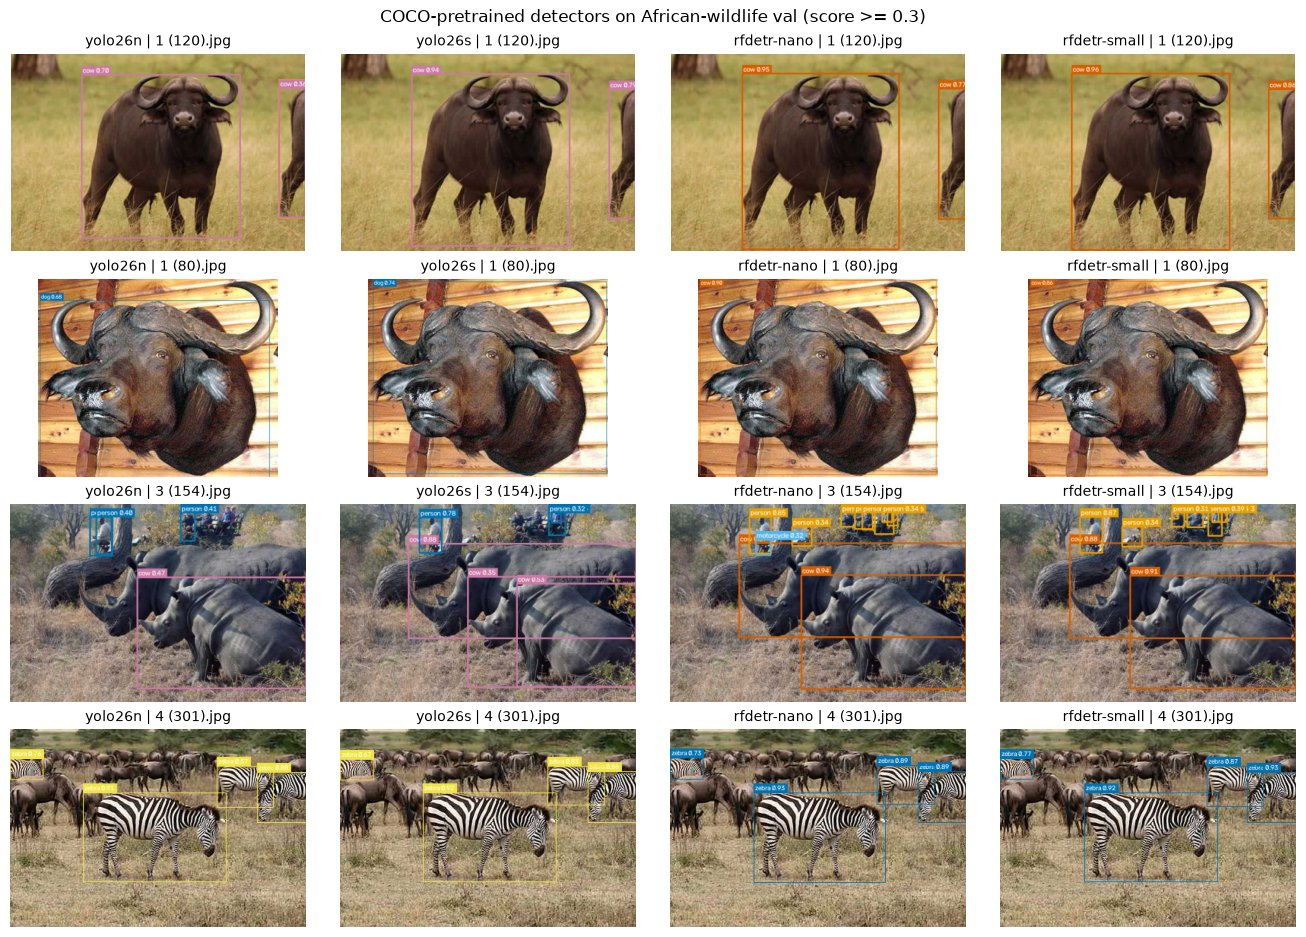

In [6]:
# --- Draw each COCO model's detections (all classes, score >= 0.3) on four val images ---
# Rows: images, columns: models. Labels show the COCO class name and the score.
show_idx = [3, 60, 120, 200]
cols = []
for name in ("yolo26n", "yolo26s", "rfdetr-nano", "rfdetr-small"):
    for i in show_idx:
        img = cvio.read_image(VAL[i].image)
        if name.startswith("yolo"):
            d = detlib.ultralytics_to_detections(yolo[name].predict(np.ascontiguousarray(img[..., ::-1]), conf=0.3, verbose=False)[0])
            names = [yolo[name].names[c] for c in d.classes]
            boxes, scores, cls = d.boxes, d.scores, d.classes
        else:
            d = rf_pred[name].predict(img, threshold=0.3)
            names = [COCO_CLASSES[c] for c in d.class_id]
            boxes, scores, cls = d.xyxy, d.confidence, d.class_id
        cols.append((i, name, cvio.resize_max(viz.draw_boxes(img, boxes, names, scores, cls), 420)))
order = [c for i in show_idx for c in cols if c[0] == i]
fig = viz.show_images([c[2] for c in order], [f"{c[1]} | {VAL[c[0]].image.name}" for c in order], ncols=4, size=3.3,
                      suptitle="COCO-pretrained detectors on African-wildlife val (score >= 0.3)")
viz.savefig(fig, PROJECT, "yolo_vs_rfdetr_qualitative")
show_jpeg(fig)

## Results

Accuracy (zero-shot mAP50-95 on elephant + zebra) against fp16 forward latency, at native and
matched resolutions; marker area is proportional to the parameter count. RTX 5060 Laptop GPU, batch 1.

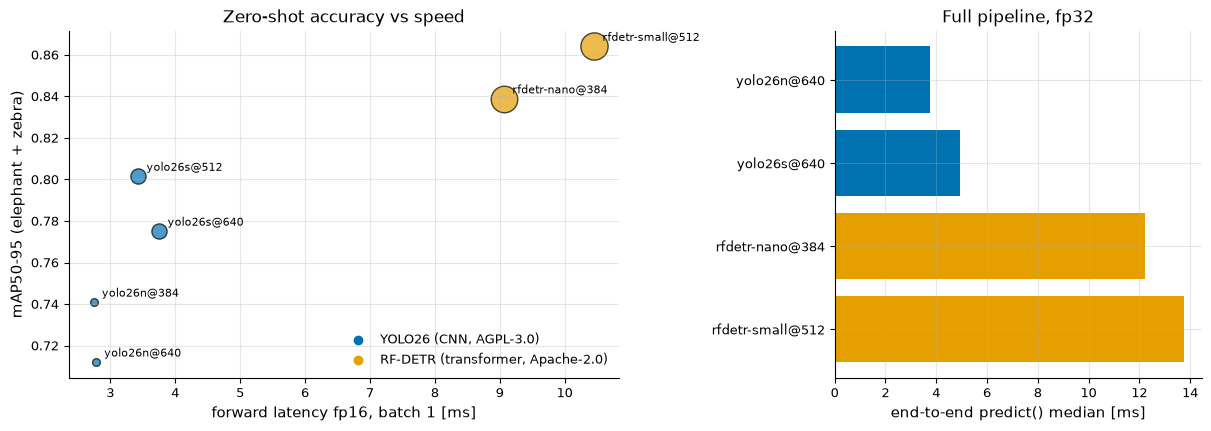

In [7]:
# --- Results figure: accuracy vs latency scatter + end-to-end predict latency ---
# Left: one point per (model, input size) in the zero-shot setting. Right: predict() medians.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, width_ratios=[3, 2])
zs = acc.xs("COCO zero-shot", level="weights")
for (name, size), row in zs.iterrows():
    lat_ms = fwd_df.loc[(name, size, "fp16"), "forward [ms]"]
    params = info.loc[name, "params [M]"]
    c = viz.color(0 if name.startswith("yolo") else 1, unit=True)
    axes[0].scatter(lat_ms, row["mAP50-95"], s=params * 12, color=c, alpha=0.7, edgecolor="k")
    axes[0].annotate(f"{name}@{size}", (lat_ms, row["mAP50-95"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[0].scatter([], [], color=viz.color(0, unit=True), label="YOLO26 (CNN, AGPL-3.0)")
axes[0].scatter([], [], color=viz.color(1, unit=True), label="RF-DETR (transformer, Apache-2.0)")
axes[0].set_xlabel("forward latency fp16, batch 1 [ms]"), axes[0].set_ylabel("mAP50-95 (elephant + zebra)")
axes[0].set_title("Zero-shot accuracy vs speed"), axes[0].legend(loc="lower right")
labels = [f"{a}@{b}" for a, b in e2e_df.index]
axes[1].barh(labels, e2e_df["predict median [ms]"], color=[viz.color(0 if lab.startswith("yolo") else 1, unit=True) for lab in labels])
axes[1].set_xlabel("end-to-end predict() median [ms]"), axes[1].set_title("Full pipeline, fp32"), axes[1].invert_yaxis()
viz.savefig(fig, PROJECT, "yolo_vs_rfdetr")
plt.show()

Summary table (zero-shot rows; accuracy, latency, memory, size, licence):

In [8]:
# --- Summary table joining accuracy, forward latency, predict latency and model info ---
# Peak VRAM column = forward-pass fp32 configuration (weights + activations at batch 1); saved to results/.
tab = zs[["mAP50", "mAP50-95", "AP50-95 elephant", "AP50-95 zebra"]].copy()
tab["forward fp32 [ms]"] = [fwd_df.loc[(n, s, "fp32"), "forward [ms]"] for n, s in tab.index]
tab["forward fp16 [ms]"] = [fwd_df.loc[(n, s, "fp16"), "forward [ms]"] for n, s in tab.index]
tab["predict [ms]"] = [e2e_df["predict median [ms]"].get((n, s), np.nan) for n, s in tab.index]
tab["peak VRAM fp32 [MiB]"] = [fwd_df.loc[(n, s, "fp32"), "peak VRAM [MiB]"] for n, s in tab.index]
tab["params [M]"] = [info.loc[n, "params [M]"] for n, _ in tab.index]
tab["licence"] = [info.loc[n, "licence"] for n, _ in tab.index]
tab.round(3).to_csv(PROJ_DIR / "results" / "nb04_yolo_vs_rfdetr.csv")
acc.round(3).to_csv(PROJ_DIR / "results" / "nb04_accuracy_all.csv")
tab.round(3)

,,mAP50,mAP50-95,AP50-95 elephant,AP50-95 zebra,forward fp32 [ms],forward fp16 [ms],predict [ms],peak VRAM fp32 [MiB],params [M],licence
model,input [px],,,,,,,,,,
yolo26n,640,0.841,0.712,0.642,0.783,2.939,2.778,3.775,32.723,2.572,AGPL-3.0
yolo26s,640,0.885,0.775,0.729,0.822,5.757,3.756,4.944,90.862,10.010,AGPL-3.0
yolo26n,384,0.887,0.741,0.706,0.775,2.749,2.743,NaN,20.342,2.572,AGPL-3.0
yolo26s,512,0.915,0.801,0.761,0.842,3.926,3.431,NaN,71.419,10.010,AGPL-3.0
rfdetr-nano,384,0.957,0.839,0.843,0.835,8.985,9.064,12.229,141.690,30.467,Apache-2.0
rfdetr-small,512,0.969,0.864,0.872,0.856,12.676,10.454,13.766,163.761,32.111,Apache-2.0


### Takeaways

* **Read the accuracy columns with the protocol in mind:** this is zero-shot transfer of COCO
  weights to a new image domain on two classes (205 boxes), not COCO val. It tests robustness to
  domain shift, and the ranking can differ from the vendors' COCO tables.
* **RF-DETR transfers clearly better.** RF-DETR Small@512 (0.864 mAP50-95) and Nano@384 (0.839) beat
  every zero-shot YOLO26 configuration (best: YOLO26s@512, 0.801), and at matched input size the gap
  is large (Nano 0.839 vs YOLO26n 0.741 at 384 px). They even beat the YOLO26 models *fine-tuned on
  this dataset* on these two classes (0.787 n, 0.766 s): the DINOv2 backbone and the larger
  pretraining set carry over well. Caveat: we cannot rule out that web images like these appeared
  in some pretraining set.
* **Resolution is part of the model.** Zero-shot YOLO26 is *more* accurate at lower input sizes on
  this dataset (n: 0.741 at 384 vs 0.712 at 640; s: 0.801 at 512 vs 0.775 at 640). Many images are
  close-ups, so at 640 px the animals are larger than most objects the model saw on COCO; a smaller
  input moves them back into the familiar scale range (a plausible explanation, not proven here).
* **YOLO26 is about 3x faster.** fp16 forward: YOLO26n@640 2.78 ms vs RF-DETR Nano 9.06 ms; full
  `predict()`: 3.77 ms vs 12.23 ms. fp16 does not speed up RF-DETR Nano at batch 1 (8.99 vs 9.06 ms),
  a sign that it is bound by kernel launches rather than arithmetic. RF-DETR also has 12x
  (Nano vs YOLO26n) and 3x (Small vs YOLO26s) more parameters, yet peak inference memory stays
  under 170 MiB for every model.
* **Fine-tuning fixed YOLO26's class gaps, not its transfer gap.** The fine-tuned YOLO26 rows learned
  rhino and buffalo (notebook 02) and improved on elephant relative to zero-shot YOLO26, yet remain
  below zero-shot RF-DETR on both classes. Fine-tuning RF-DETR itself would be the natural next
  step (see Limitations in the README).
* **Licence is a real engineering constraint.** RF-DETR's Apache-2.0 licence permits closed-source
  products; YOLO26 code, weights and fine-tuned models are AGPL-3.0 unless an Ultralytics
  Enterprise licence is bought.

## Exercises

Solutions are in `projects/03_object_detection/solutions/`.

**Exercise 1 - operating point per class.** Using the zero-shot RF-DETR Small predictions in
`all_preds`, compute precision/recall/F1 vs score threshold (`detlib.detection_flags`) and pick the
best-F1 threshold. Compare it with YOLO26s at 640. Are the score scales of the two families comparable?

In [9]:
# --- Exercise 1: best-F1 threshold, RF-DETR Small vs YOLO26s ---
# TODO: scores, _, tp = detlib.detection_flags(val2, all_preds[key], 0.5) for both keys; sweep a
#       threshold, compute P/R/F1 and report the best threshold and F1 per model.

**Exercise 2 - robot-eye view.** Run YOLO26s and RF-DETR Small on the TUM fr1_desk frames used
in notebook 01 (indices 60 and 330, `cvlab.tum.load_sequence`). Which desk objects does each
model find, and which does each miss?

In [10]:
# --- Exercise 2: TUM desk frames ---
# TODO: load the sequence, predict with both models at score >= 0.3 and draw the boxes side by side.

**Exercise 3 - latency vs batch size.** Time the forward pass of RF-DETR Nano and YOLO26n (fp16)
at batch sizes 1, 4 and 16 and plot images/s. Which model scales better with batching?

In [11]:
# --- Exercise 3: batching ---
# TODO: reuse yolo_net / rf_net, benchmark on torch.rand(B, 3, size, size) for B in (1, 4, 16),
#       and plot B / latency.